# How does Empirical Risk Minimization work?
**Session 2 · Guided exercise · 25–35 minutes + optional 5-minute extension**

**Goal:** explain what the computer calculates when it learns a straight line from data.

You need basic Python arrays and loops. Only NumPy and Matplotlib are used. In Colab, upload this notebook; in JupyterLab, open it. Run cells in order with **Shift+Enter**. All code is runnable as supplied; the tasks ask you to calculate, modify and explain. No downloads or GPU are needed. If the imports fail in a local installation, install `numpy` and `matplotlib` in that environment.

The usual abbreviation is **ERM** (Empirical Risk Minimization).

We choose the hypothesis space of straight lines:
$$h_w(x)=w_0+w_1x.$$
For each observation we calculate the squared loss, then average over the training data:
$$L_i=(y_i-h_w(x_i))^2,\qquad \widehat R(w)=\frac1n\sum_{i=1}^n L_i.$$
Training means finding parameters that minimize this average. **ERM is the objective; a search or optimization algorithm is a way to achieve it.**

## 1. Calculate one empirical risk by hand (5 min)
For three observations, use the candidate line $h(x)=1+2x$.

| Input $x$ | Observed $y$ | Prediction $h(x)$ | Residual $y-h(x)$ | Squared loss |
|---|---|---|---|---|
| 0 | 1 | ? | ? | ? |
| 1 | 4 | ? | ? | ? |
| 2 | 4 | ? | ? | ? |

**Q1.** Complete the table and calculate the mean squared loss before running the check. Why might averaging the signed residuals be misleading?

In [8]:
import numpy as np
import matplotlib.pyplot as plt

x_small = np.array([0., 1., 2.])
y_small = np.array([1., 4., 4.])
predictions = 1 + 2 * x_small
residuals = y_small - predictions
losses = residuals ** 2
print("Predictions:", predictions)
print("Residuals:  ", residuals)
print("Losses:     ", losses)
print("Empirical risk (MSE):", np.mean(losses))

Predictions: [1. 3. 5.]
Residuals:   [ 0.  1. -1.]
Losses:      [0. 1. 1.]
Empirical risk (MSE): 0.6666666666666666


## 2. Try fitting a line yourself (5 min)
We use the same 25 observations: a straight-line signal plus random noise. The fixed seed gives everyone the same data. The generating rule is visible because these data are simulated; it is not information the fitting procedure uses.

**Q2.** Change `w0` and `w1` in the second cell and run it again. Try three lines and record their MSEs. Which parameter changes the slope? Can you find a line with MSE below 10?

The vertical segments show the residuals; their squared lengths enter the loss.

In [9]:
# RandomState makes the data generation reproducible
rng = np.random.RandomState(7)
x = np.linspace(0, 10, 25)
y = 4 + 1.5 * x + rng.normal(0, 2.5, size=len(x))

# This function only sees the observed training pairs (x, y).
def empirical_risk(w0, w1):
    y_pred = w0 + w1 * x
    individual_losses = (y - y_pred) ** 2
    return np.mean(individual_losses)

w0 = 4.00, w1 = 1.50, training MSE = 5.250


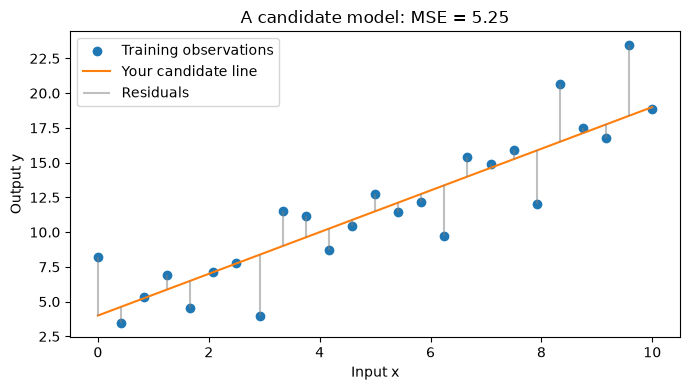

In [10]:
# TASK: edit these two parameters, then rerun this cell.
w0 = 4
w1 = 1.5

y_pred = w0 + w1 * x
manual_risk = empirical_risk(w0, w1)
print(f"w0 = {w0:.2f}, w1 = {w1:.2f}, training MSE = {manual_risk:.3f}")
plt.figure(figsize=(7, 4))
plt.scatter(x, y, label="Training observations")
plt.plot(x, y_pred, color="tab:orange", label="Your candidate line")
plt.vlines(x, y, y_pred, color="gray", alpha=0.5, label="Residuals")
plt.xlabel("Input x")
plt.ylabel("Output y")
plt.title(f"A candidate model: MSE = {manual_risk:.2f}")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Let the computer search (7 min)
Instead of guessing, try a grid of candidate intercepts and slopes. For **every pair**, the computer predicts all 25 outputs, calculates 25 squared losses, and stores their mean.

This is an explicit search over model parameters, not cross-validation or hyperparameter tuning.

**Q3.** Before running: how many candidate lines will be tested? How many predictions will be calculated in total? After running: identify the two lines of code that evaluate a candidate and select the best one.

In [11]:
intercepts = np.linspace(0, 8, 81)   # 81 candidate intercepts
slopes = np.linspace(0, 3, 61)       # 61 candidate slopes
risks = np.empty((len(intercepts), len(slopes)))

for i, candidate_w0 in enumerate(intercepts):
    for j, candidate_w1 in enumerate(slopes):
        risks[i, j] = empirical_risk(candidate_w0, candidate_w1)

# argmin returns a position; unravel_index converts it to row and column.
best_i, best_j = np.unravel_index(np.argmin(risks), risks.shape)
w0_grid = intercepts[best_i]
w1_grid = slopes[best_j]
risk_grid = risks[best_i, best_j]

print(f"Candidates evaluated: {risks.size}")
print(f"Best grid parameters (argmin): w0={w0_grid:.3f}, w1={w1_grid:.3f}")
print(f"Smallest grid risk (min): {risk_grid:.3f}")

Candidates evaluated: 4941
Best grid parameters (argmin): w0=3.900, w1=1.550
Smallest grid risk (min): 5.203


## 4. See the search result (5 min)
The left panel is **data space**: a point is an observation. The right panel is **parameter space**: a point represents an entire candidate line. Its colour gives the average training loss.

**Q4.** Explain the difference between **min** and **argmin** using your output. Is the selected line necessarily the best among *all* possible straight lines, or just the tested grid?

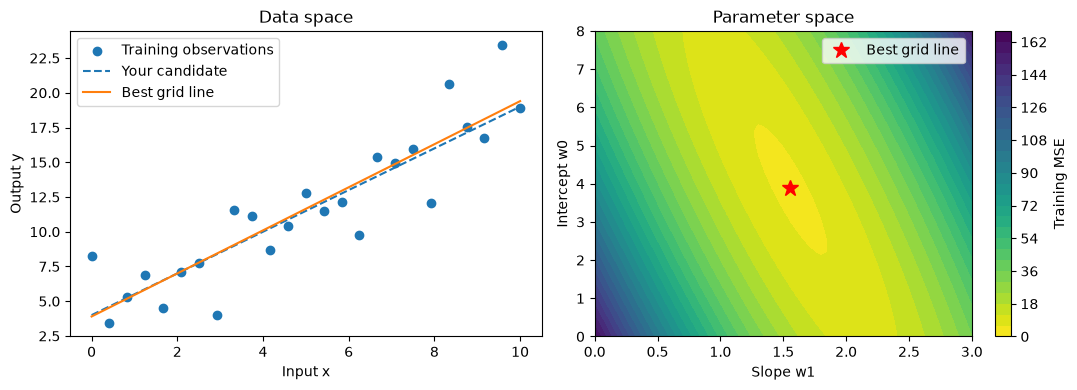

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, y, label="Training observations")
axes[0].plot(x, w0 + w1*x, "--", label="Your candidate")
axes[0].plot(x, w0_grid + w1_grid*x, label="Best grid line")
axes[0].set(xlabel="Input x", ylabel="Output y", title="Data space")
axes[0].legend()

surface = axes[1].contourf(slopes, intercepts, risks, levels=30, cmap="viridis_r")
axes[1].plot(w1_grid, w0_grid, "r*", markersize=12, label="Best grid line")
axes[1].set(xlabel="Slope w1", ylabel="Intercept w0", title="Parameter space")
axes[1].legend()
fig.colorbar(surface, ax=axes[1], label="Training MSE")
plt.tight_layout()
plt.show()

## 5. Compare with the least-squares solution (5 min)
For straight lines and squared loss, we can directly calculate the optimum using the formulas from slide 7:
$$\widehat w_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},\qquad
\widehat w_0=\bar y-\widehat w_1\bar x.$$
This minimizes the same empirical risk over **all real-valued intercepts and slopes**, rather than a finite grid. No iterative search is needed here.

**Q5.** Compare the two risks. Why can the least-squares result improve on the grid? Why does the fitted line not have exactly the generating parameters $(4,1.5)$? Does a nonzero minimum mean that training failed?

In [13]:
x_mean = np.mean(x)
y_mean = np.mean(y)
w1_exact = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
w0_exact = y_mean - w1_exact * x_mean
risk_exact = empirical_risk(w0_exact, w1_exact)

print(f"Grid:          w0={w0_grid:.4f}, w1={w1_grid:.4f}, MSE={risk_grid:.6f}")
print(f"Least squares: w0={w0_exact:.4f}, w1={w1_exact:.4f}, MSE={risk_exact:.6f}")
print(f"Generating line's training MSE: {empirical_risk(4, 1.5):.6f}")

Grid:          w0=3.9000, w1=1.5500, MSE=5.203004
Least squares: w0=3.8398, w1=1.5584, MSE=5.202037
Generating line's training MSE: 5.250271


### Your conclusion
Write three sentences explaining:
1. What is chosen in advance (model family and loss), and what is learned?
2. What operations turn a candidate line into one empirical-risk value?
3. Why does the smallest training risk not guarantee the smallest error on new data?

**Submit:** your Q1 table, three trials for Q2, answers to Q3–Q5, and this conclusion.

**Key distinction:** we optimize parameters using training observations. The empirical risk is a sample average; the true risk is an expectation over the unknown population.

## Optional: evaluate on new observations (5 min)
Freeze the least-squares model before running this cell. Generate an independent test sample from the same process and evaluate once. The parameters below are **not refitted**.

**Q6.** Are the training and test MSE identical? Must test MSE always be larger? Can a single test sample give the exact true risk?

Do not use these test results to choose new parameters or model settings. If you need to make such choices, use validation data and reserve a separate final test set.

In [ ]:
test_rng = np.random.RandomState(123)
x_test = test_rng.uniform(0, 10, 200)
y_test = 4 + 1.5*x_test + test_rng.normal(0, 2.5, size=len(x_test))
y_test_pred = w0_exact + w1_exact*x_test
test_mse = np.mean((y_test - y_test_pred)**2)
print(f"Training MSE: {risk_exact:.3f}")
print(f"Test MSE:     {test_mse:.3f}")